# Team 2 Best model inference
current best model is `FeatureMemAE` with `DINOv2` Backbone.

## Clone git repository

Every dependency is all in one.

In [42]:
%%bash

mkdir ./source

git clone https://github.com/ShimSoonYong/AD_project.git ./source

mkdir: ./source: File exists
fatal: destination path './source' already exists and is not an empty directory.


CalledProcessError: Command 'b'\nmkdir ./source\n\ngit clone https://github.com/ShimSoonYong/AD_project.git ./source\n'' returned non-zero exit status 128.

## Set directory and build Docker image

1. Change running directory with `cd`.
2. Change authority with `chmod 777 -R`
3. Build image with `docker build`

In [1]:
%%bash
cd ./source
chmod 777 -R .
docker build -t ad_project .

chmod: cannot access './dataset/FashionMNIST/raw/t10k-labels-idx1-ubyte': Permission denied
#0 building with "default" instance using docker driver

#1 [internal] load build definition from Dockerfile
#1 transferring dockerfile: 269B done
#1 DONE 0.0s

#2 [internal] load metadata for nvcr.io/nvidia/pytorch:26.09-py3
#2 DONE 0.7s

#3 [internal] load .dockerignore
#3 transferring context: 2B done
#3 DONE 0.0s

#4 [1/4] FROM nvcr.io/nvidia/pytorch:26.09-py3@sha256:6e8ccc607fc2a51e3741667b86316a0889418ba8b78ed0ba96e8d282b648a7a6
#4 resolve nvcr.io/nvidia/pytorch:26.09-py3@sha256:6e8ccc607fc2a51e3741667b86316a0889418ba8b78ed0ba96e8d282b648a7a6 0.0s done
#4 DONE 0.0s

#5 [internal] load build context
#5 transferring context: 833B done
#5 DONE 0.0s

#6 [3/4] COPY requirements.txt .
#6 CACHED

#7 [2/4] WORKDIR /workspace
#7 CACHED

#8 [4/4] RUN pip install --no-cache-dir   -r requirements.txt
#8 CACHED

#9 exporting to image
#9 exporting layers 0.0s done
#9 exporting manifest sha256:ee8d6be64d

## Run inference

In [4]:
%%bash
ls
cp ./best_MemAE_weight.pth ./source/logs/MemAE/seed42/run_01
cd ./source

docker run --rm --gpus=all --ipc=host --volume $(pwd):/workspace ad_project \
    python src/main.py \
        --models FeatureMemAE \
        --mode inference \
        --latent_dim 128 \
        --hidden_dim 256 \
        --memory_size 100

FeatureMemAE_infer.ipynb
best_MemAE_weight.pth
code submission form.ipynb
source

== PyTorch ==

NVIDIA Release 26.09 (build 453215200)
PyTorch Version 2.14.0a0+b2c75dd
Container image Copyright (c) 2026, NVIDIA CORPORATION & AFFILIATES. All rights reserved.
Copyright (c) 2014-2024 Facebook Inc.
Copyright (c) 2011-2014 Idiap Research Institute (Ronan Collobert)
Copyright (c) 2012-2014 Deepmind Technologies    (Koray Kavukcuoglu)
Copyright (c) 2011-2012 NEC Laboratories America (Koray Kavukcuoglu)
Copyright (c) 2011-2013 NYU                      (Clement Farabet)
Copyright (c) 2006-2010 NEC Laboratories America (Ronan Collobert, Leon Bottou, Iain Melvin, Jason Weston)
Copyright (c) 2006      Idiap Research Institute (Samy Bengio)
Copyright (c) 2001-2004 Idiap Research Institute (Ronan Collobert, Samy Bengio, Johnny Mariethoz)
Copyright (c) 2015      Google Inc.
Copyright (c) 2015      Yangqing Jia
Copyright (c) 2013-2016 The Caffe contributors
All rights reserved.

Various files include

/usr/local/lib/python3.12/dist-packages/torchvision/transforms/v2/_deprecated.py:42: UserWarning: The transform `ToTensor()` is deprecated and will be removed in a future release. Instead, please use `v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)])`.Output is equivalent up to float precision.
  warnings.warn(


Start main.py


/workspace/src/models/backbones/dinov2/layers/swiglu_ffn.py:45: UserWarning: xFormers is disabled (SwiGLU)
  warnings.warn("xFormers is disabled (SwiGLU)")
/workspace/src/models/backbones/dinov2/layers/swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
/workspace/src/models/backbones/dinov2/layers/attention.py:29: UserWarning: xFormers is disabled (Attention)
  warnings.warn("xFormers is disabled (Attention)")
/workspace/src/models/backbones/dinov2/layers/attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
/workspace/src/models/backbones/dinov2/layers/block.py:35: UserWarning: xFormers is disabled (Block)
  warnings.warn("xFormers is disabled (Block)")
/workspace/src/models/backbones/dinov2/layers/block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")


Running inference mode for FeatureMemAE...
Loading weights from /workspace/logs/MemAE/seed42/run_01/best_MemAE_weight.pth
AUROC: 0.808697
{
  "mode": "inference",
  "model": "FeatureMemAE",
  "run": "run_01",
  "test_metrics": {
    "auroc": 0.808697,
    "class_0_vs_2": 0.9166895,
    "class_4_vs_2": 0.7561885,
    "class_6_vs_2": 0.7532129999999999
  }
}
Running on cuda
Setting directories
Get data loaders
Finished all procedures


## Extract CSV file

Same csv with that uploaded.

In [5]:
import os
import pandas as pd
from pathlib import Path

path = next(Path(os.getcwd()).rglob("test_scores_inference.csv"))
df = pd.read_csv(path)
df

,id,dataset_index,class,anomaly,score
0,0,0,2,0,0.003403
1,1,1,6,1,0.003629
2,2,2,4,1,0.003449
3,3,3,6,1,0.003476
4,4,4,4,1,0.003671
...,...,...,...,...,...
3995,3995,3995,0,1,0.003691
3996,3996,3996,0,1,0.003564
3997,3997,3997,2,0,0.003507
3998,3998,3998,4,1,0.003444


In [6]:
df.to_csv(Path(os.getcwd()) / "scores.csv")

## Draw AUROC

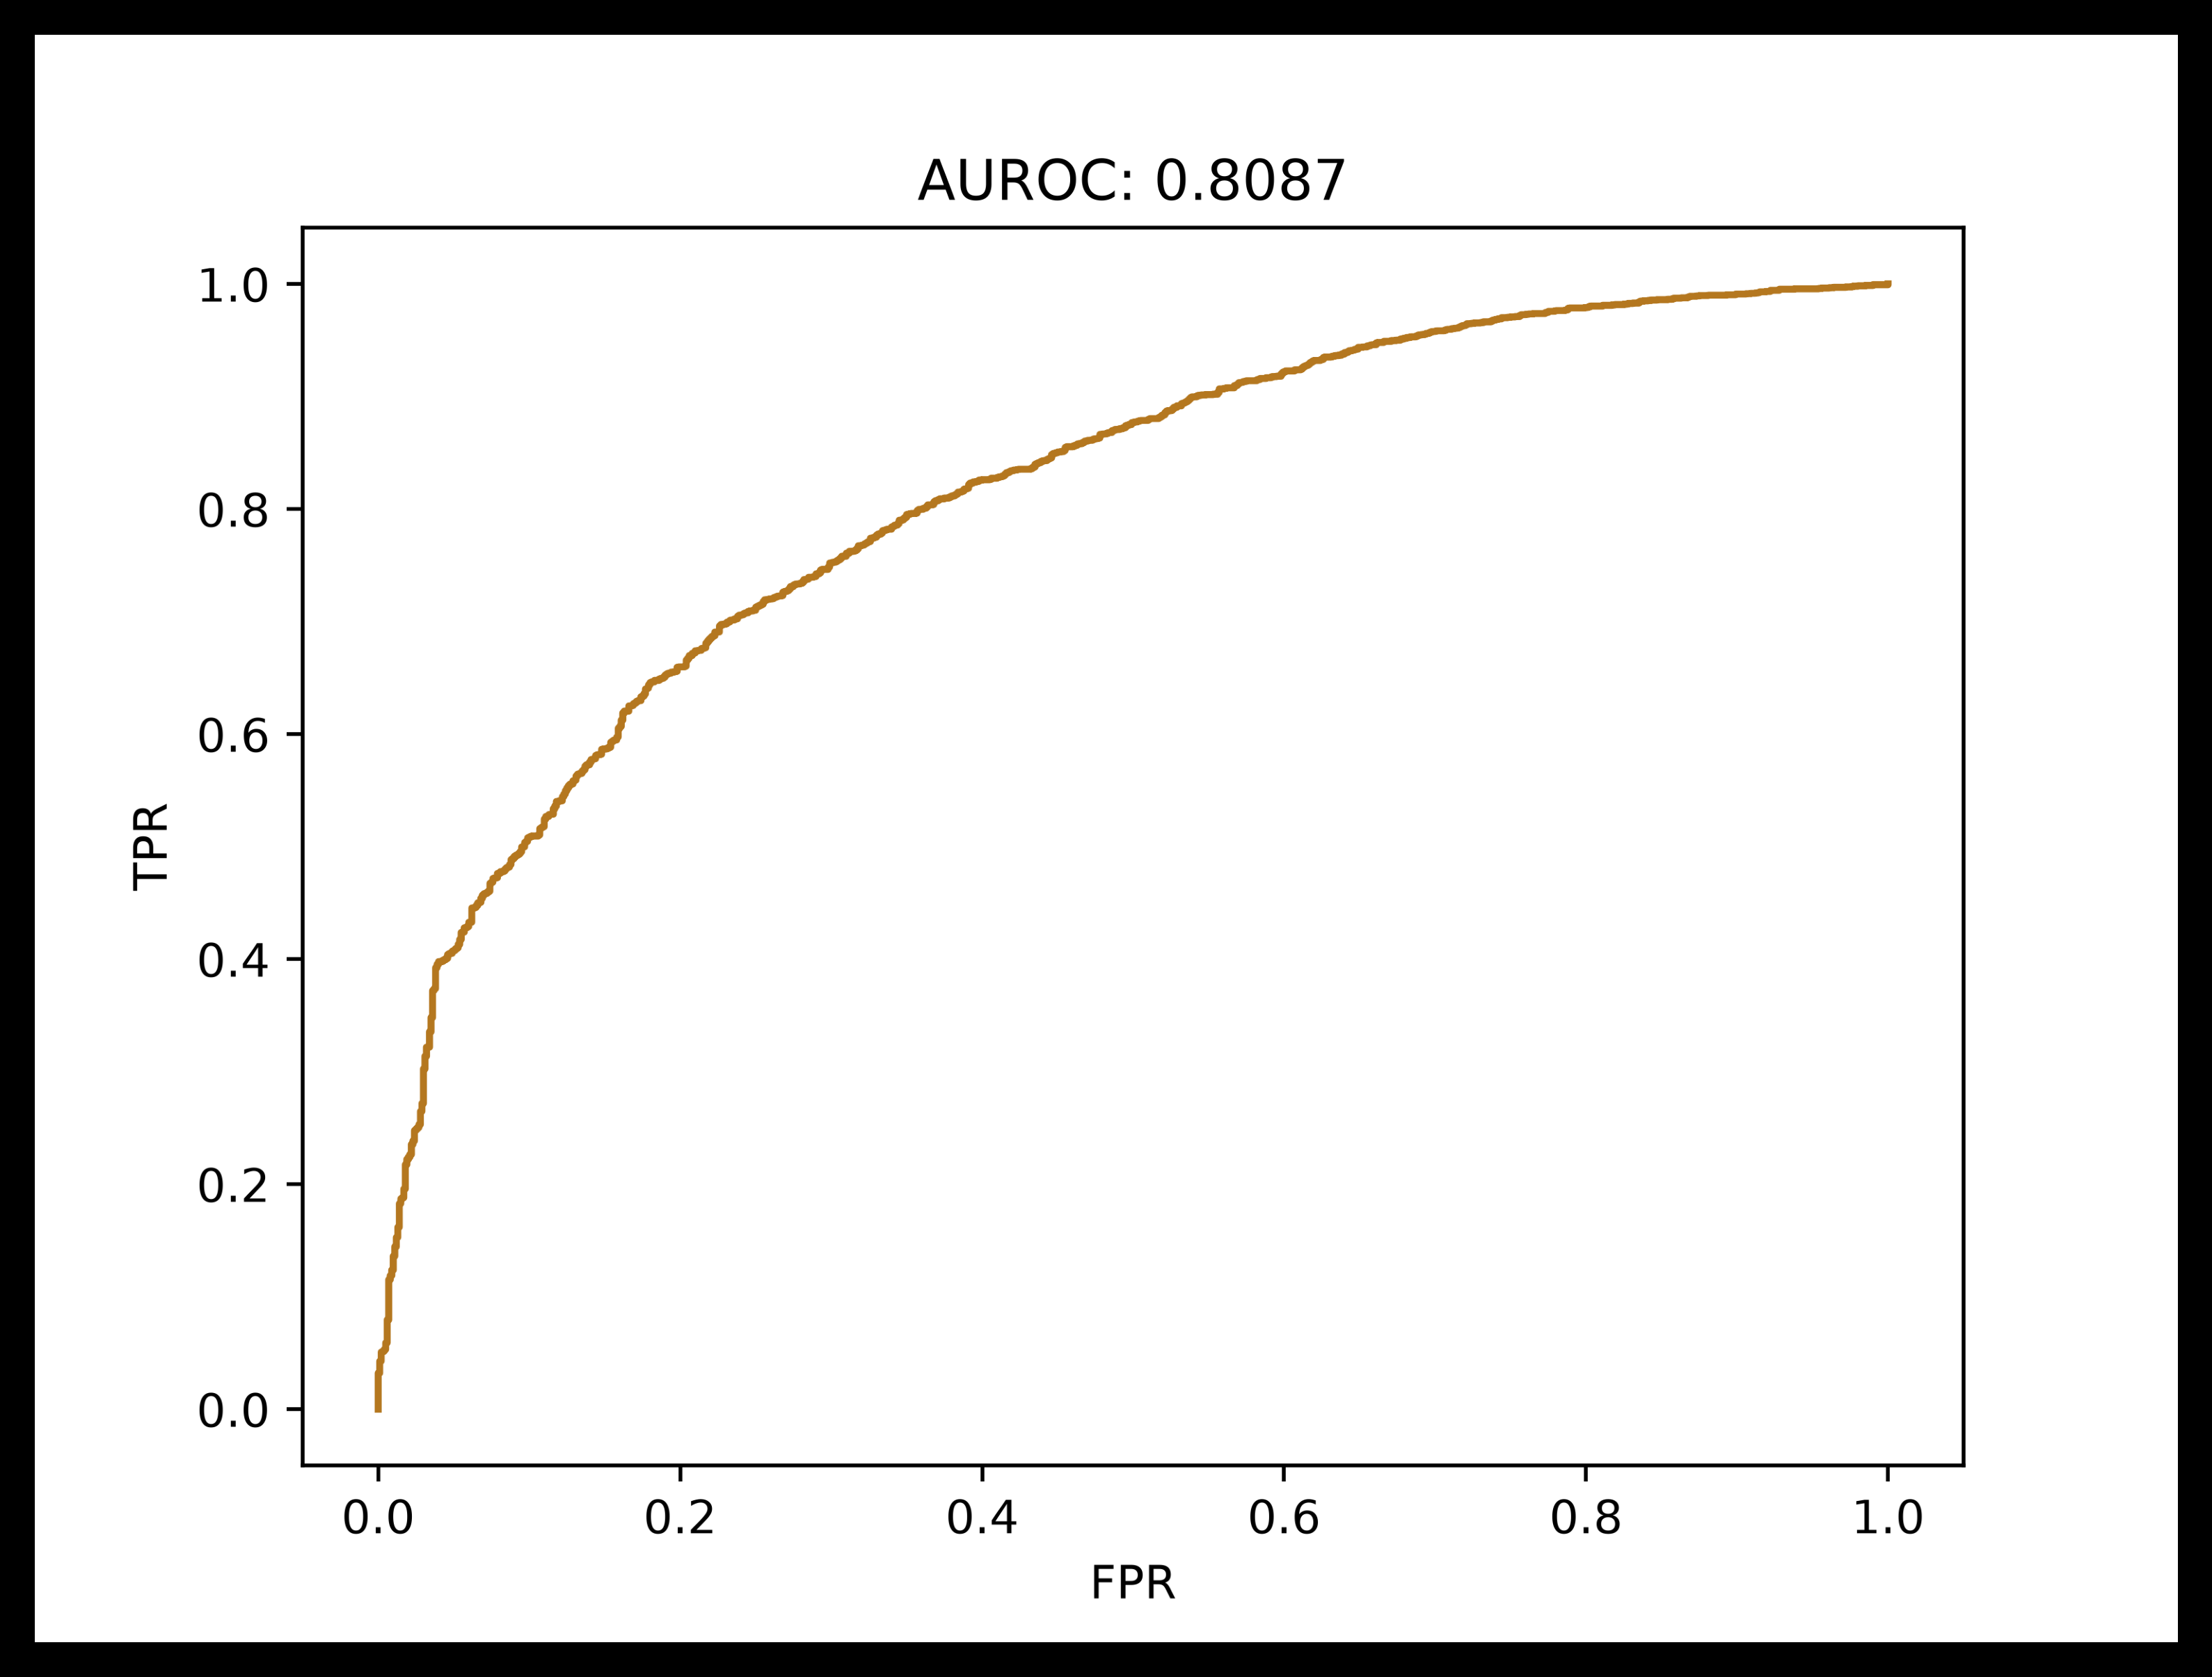

In [16]:
import cv2
import matplotlib.pyplot as plt

img = cv2.imread(next(Path(os.getcwd()).rglob("epochinference_auroc.png")))

plt.figure(figsize=(10, 6), dpi=500)
plt.axis('off')
plt.imshow(img)
plt.show()